# Аналитика маркетплейса: поиск причин падения выручки, юнит-экономика и A/B-тест


## Вводные по кейсу

Что считается верно (суммы и уникальные пользователи)

выручка (комиссия 5%), ARPU, ARPPU;
LTV, CAC, ROMI по каналам;
выручка от новых и вернувшихся клиентов;
monetary_value в RFM;
конверсия, retention, воронка, таблица сегментов (всё по user_id).
«Количество заказов» считается у меня верно, потому что В рамках анализа каждый уникальный order_id рассматривается как отдельный заказ (транзакция). Несколько заказов одного пользователя, оформленных в одну дату и время, учитываются независимо. Агрегация по пользователю и дате не применяется, поскольку она искусственно объединяла бы самостоятельные заказы в одну условную корзину, занижала количество заказов и завышала средний чек. Такой подход позволяет сохранить исходную структуру транзакций и корректно оценивать динамику количества заказов и AOV.
- средний чек пусть тоже считается верно по каждому order_id, я не буду вообще в расчетах брать сумму корзины в день
Что считается неверно (там, где ты считаешь строки или делишь на их число)
 в RFM
- Распределение стоимости заказа (медиана 7 555 руб., среднее 14 039 руб., 95-й перцентиль и т. д.): это распределение по заказам, потому что у меня один заказ это ордер айди . а внутри этого ордер айди может быть несколько позиций одного наименования которые складываются в тотал прайс - это есть итоговая сумма заказа
- 
- Frequency в RFM (order_id.count()): считает позиции. У пользователя 3 frequency равно 7, хотя было 2 покупки. Из-за этого пользователь с одной крупной корзиной из 3+ позиций попадает в f = 3 («часто покупает»). Выводы про «покупали часто» для сегментов 233 и 333 и про «1–3 заказа у большинства» от этого искажаются.
- Тезис «стабильный средний чек при падении числа заказов» тоже нужно перепроверить: если менялось число позиций в корзине, это не видно по твоим расчётам.


Маркетплейс, нашедший свою нишу и вышедший на прибыль, зарабатывает комиссию 5% с каждого заказа и активно инвестирует в привлечение пользователей через разные каналы. Во втором полугодии 2024 года маркетинговые расходы выросли, а выручка снизилась. Цель кейса: найти источники проблемы, определить точки роста и сформулировать продуктовые гипотезы.

Задачи
1. Подготовить данные: проверить типы, пропуски и дубликаты в четырёх таблицах (пользователи, события, заказы, затраты на привлечение).
2. Оценить динамику ключевых метрик за 2024 год: вовлечённость (WAU, MAU), монетизацию (выручка, количество заказов, AOV, ARPU, ARPPU), конверсию в заказ и удержание платящих пользователей по когортам.
3. Проанализировать юнит-экономику: CAC, LTV и ROMI по каналам привлечения, срок окупаемости когорт, структуру выручки (новые и вернувшиеся клиенты) и маркетингового бюджета.
4. Выявить проблемные и сильные сегменты пользователей: сегменты покупателей и RFM-сегменты.
5. Построить пользовательскую воронку и определить этапы с наибольшим снижением аудитории: общую, по устройствам и операционным системам, по каналам привлечения.
6. Сформулировать гипотезы для улучшения продукта и маркетинга, указав, на каких данных основана каждая.

# Блок кода и расчета метрик

## Загрузка исторических данных и их предобработка

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.express as px
import plotly.graph_objects as go


In [33]:
orders = pd.read_csv('orders_clear.csv', parse_dates=['order_date', 'order_week', 'order_month'])
campaign_costs = pd.read_csv('campaign_costs_clear.csv', parse_dates=['spend_month'])
users = pd.read_csv('users_clear.csv', parse_dates=['registration_date', 'cohort_week', 'cohort_month'])
events = pd.read_csv('events_clear.csv', parse_dates=['event_date', 'event_week', 'event_month'])

## Предобработка данных

Предобработка вынесена в отдельный блок, чтобы не перегружать проект. Данные проверены на пропуски, дубликаты и корректность типов; удалены повторные записи событий и заказов. Дальнейший анализ выполнен на очищенных данных, а ход очистки описан в блоке с предобработкой который можно найти в файле `data_preprocessing.ipynb`

## Ключевые метрики

На этом этапе выполнена верхнеуровневая оценка состояния продукта на агрегированных данных, без разбивки по каналам и сегментам. Цель: понять, как менялись масштаб бизнеса, активность аудитории и монетизация в течение 2024 года, и определить, когда и по каким метрикам проявляется спад выручки.

Последовательно рассматриваются:

- выручка (комиссия 5% от суммы заказов);
- вовлеченность (WAU и MAU);
- количество заказов и средний чек;
- ARPU и ARPPU: доход на одного активного и на одного платящего пользователя;
- конверсия в заказ;
- retention платящих пользователей по когортам: доля покупателей, которые возвращаются за повторной покупкой.

Результат этапа: выводы о динамике основных метрик и сигналы, которые затем разбираются подробно на уровне юнит-экономики, воронок и сегментов.

## Общая выручка

,order_month,total_price,revenue
1,2024-01-01,12853222.23,642661.11
2,2024-02-01,25820076.52,1291003.83
3,2024-03-01,38226803.72,1911340.19
4,2024-04-01,42406554.11,2120327.71
5,2024-05-01,49149201.52,2457460.08
6,2024-06-01,41875283.43,2093764.17
7,2024-07-01,48548210.99,2427410.55
8,2024-08-01,48975196.68,2448759.83
9,2024-09-01,38444597.28,1922229.86
10,2024-10-01,34170797.40,1708539.87


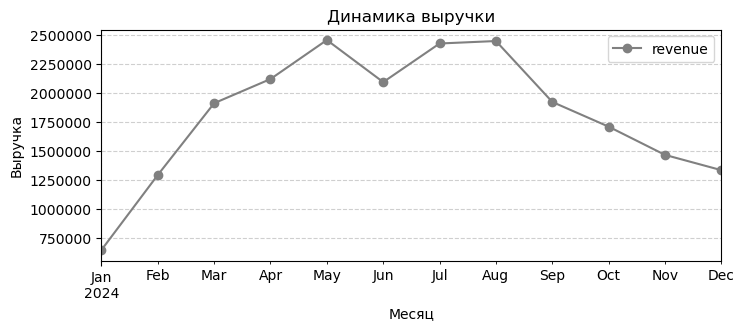

In [44]:
# Считаем revenue c группировкой по месяцам
revenue = orders.groupby('order_month')['total_price'].sum().reset_index()
revenue['revenue'] = (revenue['total_price'] * 0.05).round(2)

revenue.index = range(1, len(revenue) + 1)
display(revenue)

revenue.plot(
    kind="line", x="order_month", y="revenue", marker="o", color='gray', figsize=(8, 3)
)

plt.title("Динамика выручки")
plt.xlabel("Месяц")  
plt.ylabel("Выручка") 
plt.ticklabel_format(style='plain', axis='y')  
plt.grid(True, linestyle="--", alpha=0.6)  
plt.legend(["revenue"], loc="upper right")
plt.show()

В первом полугодии 2024 года наблюдался устойчивый рост выручки с пиковыми значениями в мае (2.45 млн) и августе (2.44 млн). Начиная с сентября, наметился нисходящий тренд: к декабрю показатель сократился до 1.33 млн, что составляет около 54% от уровня майского максимума. Текущая динамика указывает на наличие значимых факторов, сдерживающих продажи во втором полугодии, и требует детального исследования причин снижения активности пользователей или объема заказов.

## Метрики вовлеченности

Рассчитываем WAU и MAU. Учитывая специфику маркетплейса DAU не считаем, покупки на маркетплейсе совершаются нерегулярно, поэтому дневная активность сильно колеблется и при годовом горизонте анализа не добавляет информации по сравнению с недельной и месячной. Активным считается пользователь, совершивший любое действие, кроме технических событий (user_login и user_logout).

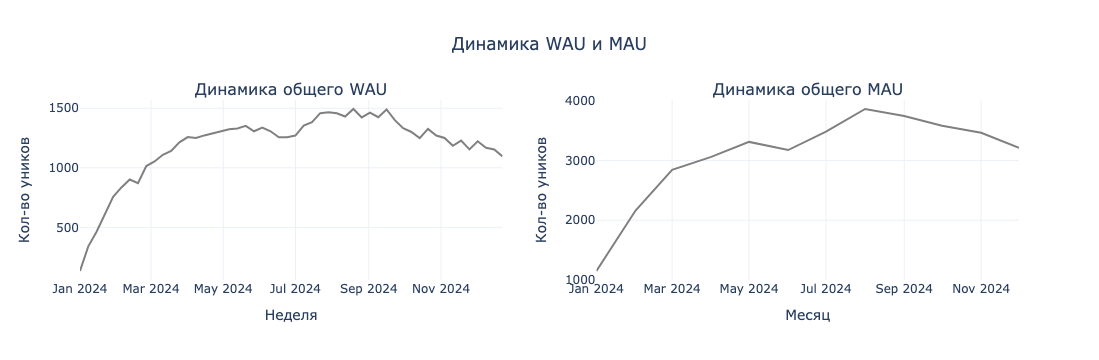

In [49]:
# Убираем последнюю неделю декабря 2024 года, так как ранее в данных заметила резкое падение, которое не меняет сути, но на графике выглядит пугающе
events_filtered = events[~((events['event_week'].dt.year == 2024) & (events['event_week'].dt.month == 12) & (events['event_week'] >= '2024-12-25'))]

events_mau_wau = events_filtered.query('event_type not in ("user_login", "user_logout")')
wau = events_mau_wau.groupby('event_week')['user_id'].nunique().reset_index().rename(columns={'user_id': 'wau'})
mau = events_mau_wau.groupby('event_month')['user_id'].nunique().reset_index().rename(columns={'user_id': 'mau'})


fig = make_subplots(
    rows=1, cols=2, 
    subplot_titles=('Динамика общего WAU', 'Динамика общего MAU')
)

trace_wau = px.line(wau, x='event_week', y='wau').update_traces(line=dict(color='gray', width=2)).data[0]
fig.add_trace(trace_wau, row=1, col=1)

trace_mau = px.line(mau, x='event_month', y='mau').update_traces(line=dict(color='gray', width=2)).data[0]
fig.add_trace(trace_mau, row=1, col=2)


fig.update_layout(
    title_text="Динамика WAU и MAU",
    title_x=0.5,
    showlegend=False,
    template='plotly_white',  
    hovermode='x unified'     
)

fig.update_xaxes(title_text="Неделя", row=1, col=1)
fig.update_xaxes(title_text="Месяц", row=1, col=2)
fig.update_yaxes(title_text="Кол-во уников", row=1, col=1)
fig.update_yaxes(title_text="Кол-во уников", row=1, col=2)

fig.show()

Динамика WAU демонстрирует уверенный рост в первой половине года с выходом на плато в районе 1200–1350 активных пользователей в неделю. Начиная с сентября, наблюдается постепенное снижение показателя.

График MAU подтверждает общую тенденцию: после достижения максимума в августе (около 3800 пользователей), количество ежемесячно активных пользователей перешло к плавному снижению. Что в сочетании с динамикой WAU свидетельствует о постепенном оттоке аудитории и снижении общей вовлеченности во втором полугодии.

## Средний чек и кол-во заказов

В рамках анализа каждый уникальный order_id рассматривается как отдельный заказ (транзакция). Несколько заказов одного пользователя, оформленных в одну дату и время, учитываются независимо. Агрегация по пользователю и дате не применяется, поскольку она искусственно объединяла бы самостоятельные заказы в одну условную корзину, занижала количество заказов и завышала средний чек. Такой подход позволяет сохранить исходную структуру транзакций и корректно оценивать динамику количества заказов и AOV.

,order_month,total_price,order_count,aov
1,2024-01-01,12853222.23,957,13430.74
2,2024-02-01,25820076.52,1902,13575.22
3,2024-03-01,38226803.72,2758,13860.33
4,2024-04-01,42406554.11,3098,13688.36
5,2024-05-01,49149201.52,3489,14086.90
6,2024-06-01,41875283.43,3033,13806.56
7,2024-07-01,48548210.99,3385,14342.16
8,2024-08-01,48975196.68,3365,14554.29
9,2024-09-01,38444597.28,2737,14046.25
10,2024-10-01,34170797.40,2459,13896.22


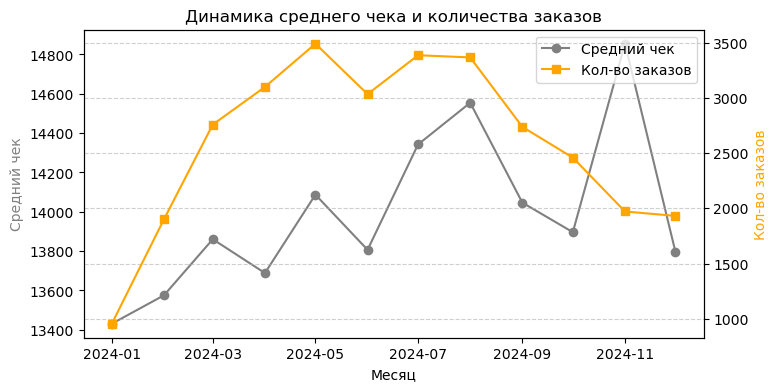

In [54]:
#Средний чек
aov = orders.groupby('order_month').agg(
    total_price=('total_price', 'sum'),
    order_count=('order_id', 'nunique')
).reset_index()
aov['aov'] = (aov['total_price'] / aov['order_count']).round(2)

aov.index = range(1, len(aov) + 1)
display(aov)

fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(aov['order_month'], aov['aov'], marker="o", color='gray', label="Средний чек")
ax1.set_ylabel("Средний чек", color='gray')
ax1.set_xlabel("Месяц")

ax2 = ax1.twinx()
ax2.plot(aov['order_month'], aov['order_count'], marker="s", color='orange', label="Кол-во заказов")
ax2.set_ylabel("Кол-во заказов", color='orange')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, ["Средний чек", "Кол-во заказов"], loc="upper right")

plt.title("Динамика среднего чека и количества заказов")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Количество заказов росло в первом полугодии: с 957 в январе до пика в 3489 в мае, после чего держалось на уровне 3 000–3 400 до августа и затем снизилось до 1 932 в декабре (−45% от майского максимума). Средний чек при этом остаётся стабильным и колеблется в узком диапазоне 13,4–14,9 тыс. руб. без выраженного тренда (максимум в ноябре, 14 854 руб.). 

### Динамика ARPU и ARPPU

Кол-во пропусков после объединения:
order_month     0
revenue         0
paying_users    0
mau             0
ARPPU           0
ARPU            0
dtype: int64


,order_month,paying_users,mau,ARPU,ARPPU
1,2024-01-01,454,1149,559.32,1415.55
2,2024-02-01,839,2162,597.13,1538.74
3,2024-03-01,1165,2844,672.06,1640.64
4,2024-04-01,1324,3059,693.14,1601.46
5,2024-05-01,1404,3310,742.44,1750.33
6,2024-06-01,1230,3174,659.66,1702.25
7,2024-07-01,1385,3481,697.33,1752.64
8,2024-08-01,1385,3861,634.23,1768.06
9,2024-09-01,1163,3744,513.42,1652.82
10,2024-10-01,999,3581,477.11,1710.25


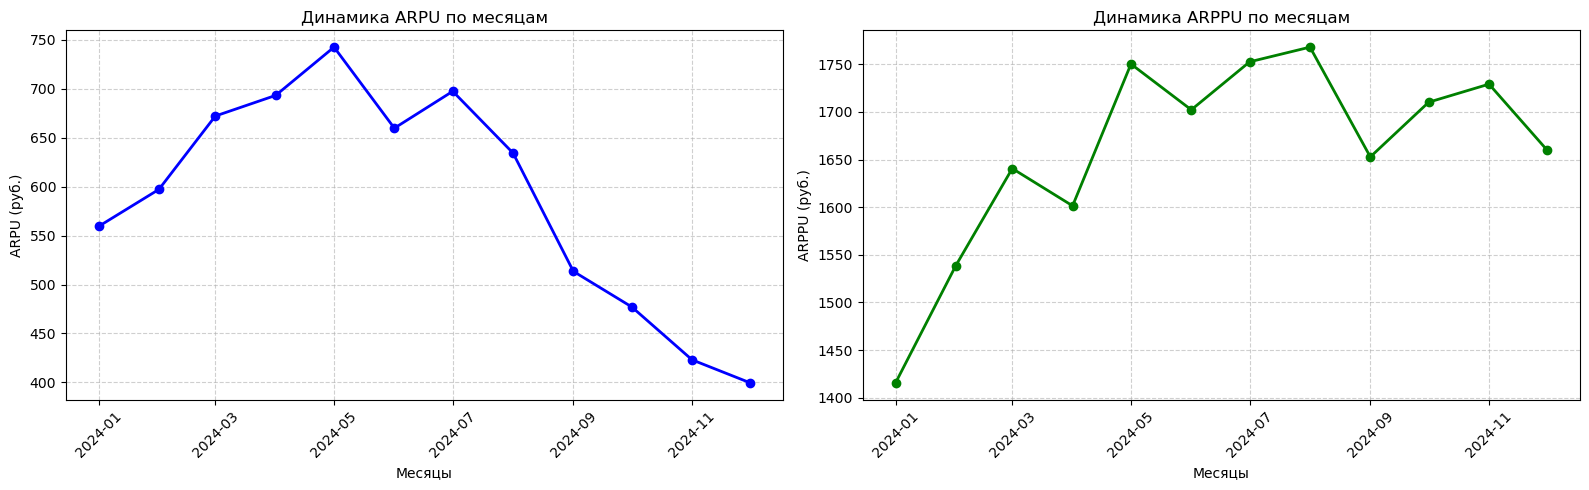

In [58]:
# Считаем выручку маркетплейса по месяцам (5% комиссии)
revenue_sum = orders.groupby('order_month')['total_price'].sum().reset_index()
revenue_sum['revenue'] = (revenue_sum['total_price'] * 0.05).round(2)

#  Считаем платящих уников
paying_users = orders.groupby('order_month')['user_id'].nunique().reset_index()
paying_users = paying_users.rename(columns={'user_id': 'paying_users'})

#  Считаем всех активных уников 
active_users = events.groupby('event_month')['user_id'].nunique().reset_index()
active_users = active_users.rename(columns={'user_id': 'mau'})

merged_df = pd.merge(revenue_sum[['order_month', 'revenue']], paying_users, on='order_month')


merged_df = pd.merge(
    merged_df, 
    active_users, 
    left_on='order_month', 
    right_on='event_month', 
    how='left'
)

# Удаляем дубли после мерджа 
merged_df = merged_df.drop(columns=['event_month'])

merged_df['ARPPU'] = (merged_df['revenue'] / merged_df['paying_users']).round(2)
merged_df['ARPU'] = (merged_df['revenue'] / merged_df['mau']).round(2)

# Проверка пропусков после объединения
print('Кол-во пропусков после объединения:')
print(merged_df.isna().sum())

merged_df.index = range(1, len(merged_df) + 1)
display(merged_df[['order_month', 'paying_users', 'mau', 'ARPU', 'ARPPU']])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(merged_df['order_month'], merged_df['ARPU'], color='blue', marker='o', linewidth=2)
ax1.set_title('Динамика ARPU по месяцам')
ax1.set_xlabel('Месяцы')
ax1.set_ylabel('ARPU (руб.)')
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.tick_params(axis='x', rotation=45)

ax2.plot(merged_df['order_month'], merged_df['ARPPU'], color='green', marker='o', linewidth=2)
ax2.set_title('Динамика ARPPU по месяцам')
ax2.set_xlabel('Месяцы')
ax2.set_ylabel('ARPPU (руб.)')
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


ARPU вырос в первом полугодии до максимума в мае (742 руб.), затем снизился почти вдвое и к декабрю составил 399 руб. ARPPU при этом остаётся стабильным (1 650–1 770 руб. во втором полугодии): платящие пользователи приносят доход на прежнем уровне. Значит, снижение ARPU связано не с изменением дохода на одного платящего, а с сокращением доли платящих среди активных пользователей.

## Конверсия в заказ

,month,total_users,paid_users,cr_%
1,2024-01-01,1149,454,39.51
2,2024-02-01,2162,839,38.81
3,2024-03-01,2844,1165,40.96
4,2024-04-01,3059,1324,43.28
5,2024-05-01,3310,1404,42.42
6,2024-06-01,3174,1230,38.75
7,2024-07-01,3481,1385,39.79
8,2024-08-01,3861,1385,35.87
9,2024-09-01,3744,1163,31.06
10,2024-10-01,3581,999,27.90


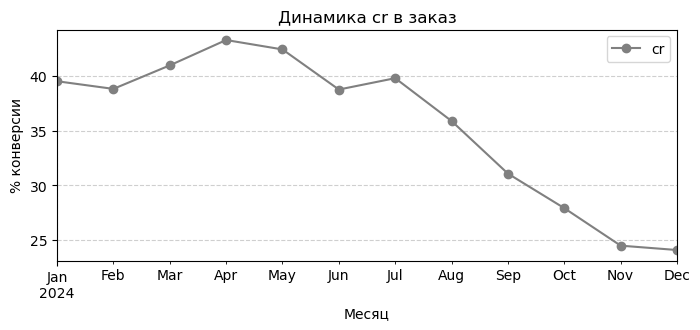

In [62]:
#  числитель уники из orders
count_paid = orders.groupby('order_month')['user_id'].nunique().reset_index()
count_paid.columns = ['month', 'paid_users']

#  знаменатель  уники из events
count_total = events.groupby('event_month')['user_id'].nunique().reset_index()
count_total.columns = ['month', 'total_users']

cr_df = count_total.merge(count_paid, on='month', how='left')

# Заполняем пропуски нулями, если в какой-то месяц вдруг не было продаж
cr_df['paid_users'] = cr_df['paid_users'].fillna(0)
cr_df['cr_%'] = ((cr_df['paid_users'] / cr_df['total_users']) * 100).round(2)

cr_df.index = range(1, len(aov) + 1)
display(cr_df)

cr_df.plot(
    kind="line", x="month", y="cr_%", marker="o",color='gray', figsize=(8, 3)
)

plt.title("Динамика cr в заказ")
plt.xlabel("Месяц")  
plt.ylabel("% конверсии") 
plt.grid(True, linestyle="--", alpha=0.6) 
plt.legend(["cr"], loc="upper right")
plt.show()


Конверсия в заказ достигла пиковых значений в апреле (43,28%) и мае (42,42%), после чего устойчиво снижалась и к декабрю составила 24,07%. Тенденция согласуется с ранее выявленным снижением вовлеченности и удержания аудитории.

## Retention по когортам

Retention можно считать по разным действиям пользователя, поэтому сначала нужно определить, что считать возвращением. Для маркетплейса в первую очередь важны покупки. Поэтому вернувшимся считается пользователь, который оформил заказ в одном из месяцев после месяца своей первой покупки. Когорты формируются по месяцу первого заказа, а retention показывает долю покупателей когорты, сделавших заказ в каждом следующем месяце.

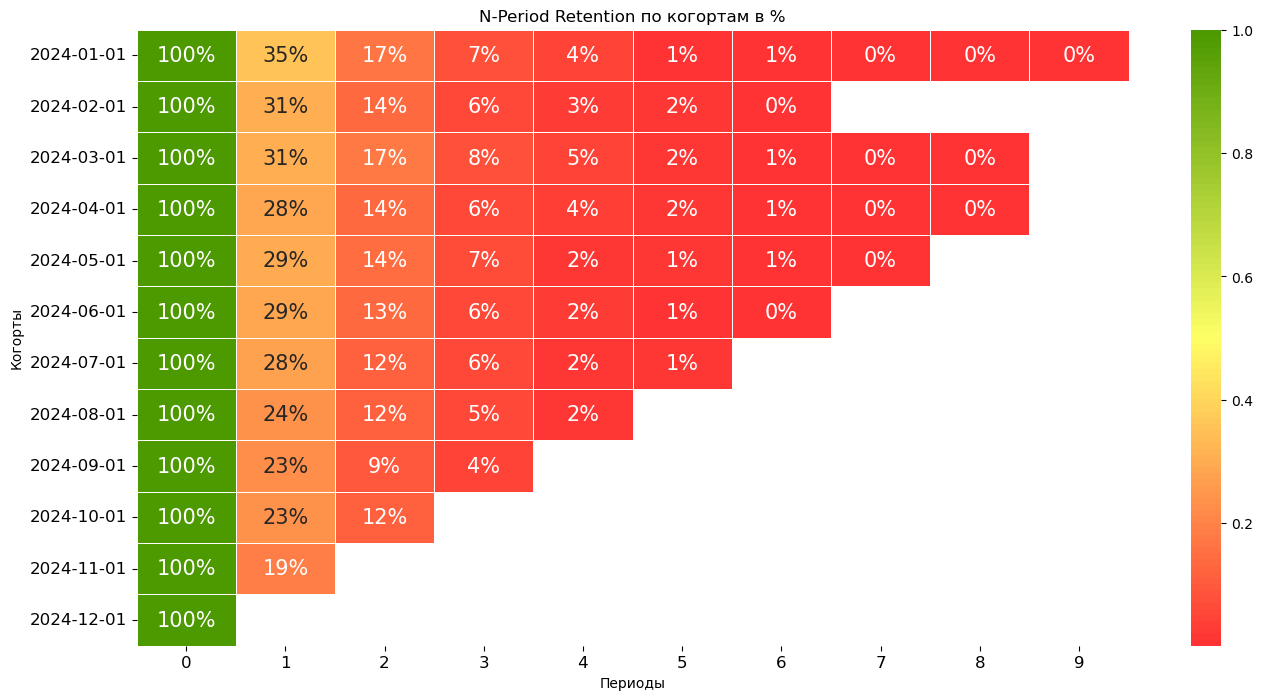

In [67]:
#Расчет ретенш, сначала считаем дату первого заказа 
orders['first_order_month'] = orders.groupby('user_id')['order_month'].transform('min')

orders['n_period'] = (
    orders['order_month'].dt.to_period('M').astype('int64')
    - orders['first_order_month'].dt.to_period('M').astype('int64')
)


data_pivot = pd.pivot_table(orders,
                            values='user_id',
                            index='first_order_month',
                            columns='n_period',
                            aggfunc=pd.Series.nunique).fillna(0).astype(int)

# Каждое значение строки датафрейма делим на значение в периоде 0 
data_pivot = data_pivot.div(data_pivot[0], axis=0)

# Заменяем нули на пустые значения NaN. 
data_pivot[data_pivot == 0] = float('nan')

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100) # красивые цвета heatmap

# Для корректного отображения индекса приведём его к типу ('%Y-%m-%d')
data_pivot.index = pd.to_datetime(data_pivot.index).strftime('%Y-%m-%d')

plt.subplots(figsize=(16,8))
sns.heatmap(data_pivot,
           cmap=cmap,
           annot=True,
           fmt='.0%',
           linewidth=0.5,
           annot_kws={"size": 15})

plt.title('N-Period Retention по когортам в %')
plt.xlabel('Периоды')
plt.ylabel('Когорты')
plt.yticks(rotation=0)
plt.tick_params(labelsize=12) 
plt.show()

Удержание платящих пользователей устойчиво снижается от когорты к когорте. В месяце 1 (следующем после месяца первой покупки) повторный заказ оформили 35% пользователей январской когорты 2024 года, а для ноябрьской когорты этот показатель сократился до 19%.
В большинстве когорт доля вернувшихся резко падает уже после месяца 0 (месяц первой покупки) и к 4–5 месяцу приближается к нулю. Это указывает на слабое долгосрочное удержание: клиенты перестают совершать повторные покупки вскоре после первого заказа.

**Промежуточный вывод**

С сентября 2024 года выручка устойчиво снижается: с 2,45 млн руб. в августе до 1,33 млн в декабре (−46%). Причина в сокращении числа заказов (с пика 3 489 в мае до 1 932 в декабре), а не в стоимости заказа: средний чек остаётся стабильным (13,4–14,9 тыс. руб.). ARPU снизился почти вдвое (с 742 до 399 руб.) при стабильном ARPPU, то есть платящие пользователи приносят доход на прежнем уровне, а сократилась их доля среди активных: конверсия в заказ упала с 43% в апреле до 24% в декабре. Кроме того, ухудшилось удержание: повторный заказ в следующем месяце после первой покупки оформляли 35% пользователей январской когорты и лишь 19% ноябрьской. 

Таким образом, снижение выручки связано с ослаблением притока платящих пользователей и их возвращаемости, и далее нужно выяснить, через какие каналы привлекается аудитория и окупаются ли вложения в её привлечение.

## Оценка метрик монетизации и юнит-экономики

На этом этапе оценивается, сколько продукт зарабатывает на привлеченных пользователях и сколько тратит на их привлечение. Расчет строится по когортам: пользователи группируются по месяцу первого заказа и каналу привлечения, а выручка (комиссия 5%) накапливается по месяцам жизни когорты. В расчёт CAC входят только платящие пользователи. Канал Direct в расчёты CAC, LTV и ROMI не входит: бюджет на него есть, но пользователей с этим каналом в данных нет.

Последовательно рассматриваются:

- CAC по каналам привлечения: сколько стоит один платящий клиент в каждом канале;
- кумулятивный ROMI по каналам: окупает ли канал затраты и за какое время;
- retention по каналам: какие каналы приводят пользователей, которые возвращаются за повторными покупками;
- новые и вернувшиеся клиенты: из чего складывается выручка и за счёт кого она снижается;
- выручка и затраты по каналам, а также структура маркетингового бюджета по каналам и месяцам 2024 года: как распределены затраты и какой итоговый ROMI у каждого канала.

## Расчет СAC по каналам привлечения

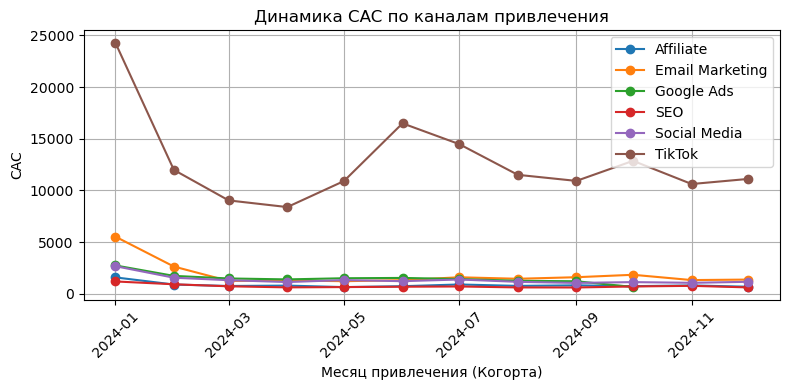

In [74]:
# Выручка маркетплейса: комиссия 5% от суммы заказа
orders['revenue'] = orders['total_price'] * 0.05

# Подтягиваем к заказам канал привлечения
df_merged = orders.merge(
    users[['user_id', 'acq_channel']],
    on='user_id',
    how='left'
)

# Номер месяца жизни: разница календарных месяцев (месяц 0 = месяц первой покупки)
df_merged['N_month'] = ((df_merged['order_month'].dt.year * 12 + df_merged['order_month'].dt.month)
                        - (df_merged['first_order_month'].dt.year * 12 + df_merged['first_order_month'].dt.month))

# 1. Выручка пользователя по месяцам жизни (только месяцы, когда были заказы)
user_rev = (df_merged.groupby(['user_id', 'acq_channel', 'first_order_month', 'N_month'])['revenue']
            .sum().reset_index())

# 2. Сколько месяцев жизни доступно пользователю (данные заканчиваются в последнем месяце заказов)
last = df_merged['order_month'].max()
users_base = user_rev[['user_id', 'acq_channel', 'first_order_month']].drop_duplicates()
users_base['max_n'] = ((last.year * 12 + last.month)
                       - (users_base['first_order_month'].dt.year * 12 + users_base['first_order_month'].dt.month))

# 3. Строка на каждый месяц жизни пользователя: от 0 до последнего доступного
grid = users_base.assign(N_month=users_base['max_n'].apply(lambda n: list(range(n + 1)))).explode('N_month')
grid['N_month'] = grid['N_month'].astype(int)

# 4. Подставляем реальную выручку; в месяцы без заказов ставим 0, и только после этого считаем накопленную сумму
df_LTV = (grid.drop(columns='max_n')
          .merge(user_rev, on=['user_id', 'acq_channel', 'first_order_month', 'N_month'], how='left'))
df_LTV['revenue'] = df_LTV['revenue'].fillna(0)

df_LTV = df_LTV.sort_values(by=['user_id', 'N_month'])
df_LTV['LTV'] = df_LTV.groupby('user_id')['revenue'].cumsum()

# Количество платящих клиентов для каждой пары (канал, месяц первой покупки)
client_counts = df_LTV.groupby(['acq_channel', 'first_order_month'])['user_id'].nunique().reset_index()
client_counts.columns = ['acq_channel', 'first_order_month', 'unique_customers']

# Объединяем маркетинговые бюджеты с количеством клиентов
# (месяц затрат spend_month сопоставляется с месяцем первой покупки first_order_month)
cac_data = campaign_costs.merge(
    client_counts,
    left_on=['spend_month', 'acq_channel'],
    right_on=['first_order_month', 'acq_channel'],
    how='left'
)

# Если платящих клиентов не было, количество равно 0
cac_data['unique_customers'] = cac_data['unique_customers'].fillna(0)
cac_data['CAC'] = cac_data['budget'] / cac_data['unique_customers']

# Если платящих клиентов не было, CAC не определён
cac_data['CAC'] = cac_data['CAC'].replace([np.inf, -np.inf], np.nan)

df_LTV_CAC = df_LTV.merge(
    cac_data[['first_order_month', 'acq_channel', 'CAC']],
    on=['first_order_month', 'acq_channel'],
    how='left'
)

# Для графика берём по одной точке CAC для каждой когорты и канала
cac_grouped = df_LTV_CAC.groupby(['first_order_month', 'acq_channel'])['CAC'].first().reset_index()

plt.figure(figsize=(8, 4))

# Линия для каждого канала привлечения
for channel in cac_grouped['acq_channel'].unique():
    df_plot = cac_grouped[cac_grouped['acq_channel'] == channel]
    plt.plot(df_plot['first_order_month'], df_plot['CAC'], marker='o', label=channel)

plt.xticks(rotation=45)
plt.xlabel('Месяц привлечения (Когорта)')
plt.ylabel('CAC')
plt.title('Динамика CAC по каналам привлечения')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

CAC существенно различается между каналами. Самое дорогое привлечение на протяжении всего периода показывает TikTok: от 8 389 до 24 304, тогда как наиболее низкий CAC у SEO (610–1 194 руб) и Affiliate (648–1 587 руб)

## Кумулятивный ROMI по каналам привлечения

Для расчета ROMI по каждому каналу и месяцу жизни пользователей суммируются накопленная выручка и затраты на привлечение. Из суммарной выручки вычитаются затраты на привлечение, а полученная разница делится на сумму затрат. Январь 2024 года принимается за нулевой месяц жизни когорты (N_month = 0), декабрь - за одиннадцатый (N_month = 11). Красная пунктирная линия на графике обозначает точку окупаемости: при ROMI = 0% выручка равна затратам на привлечение.

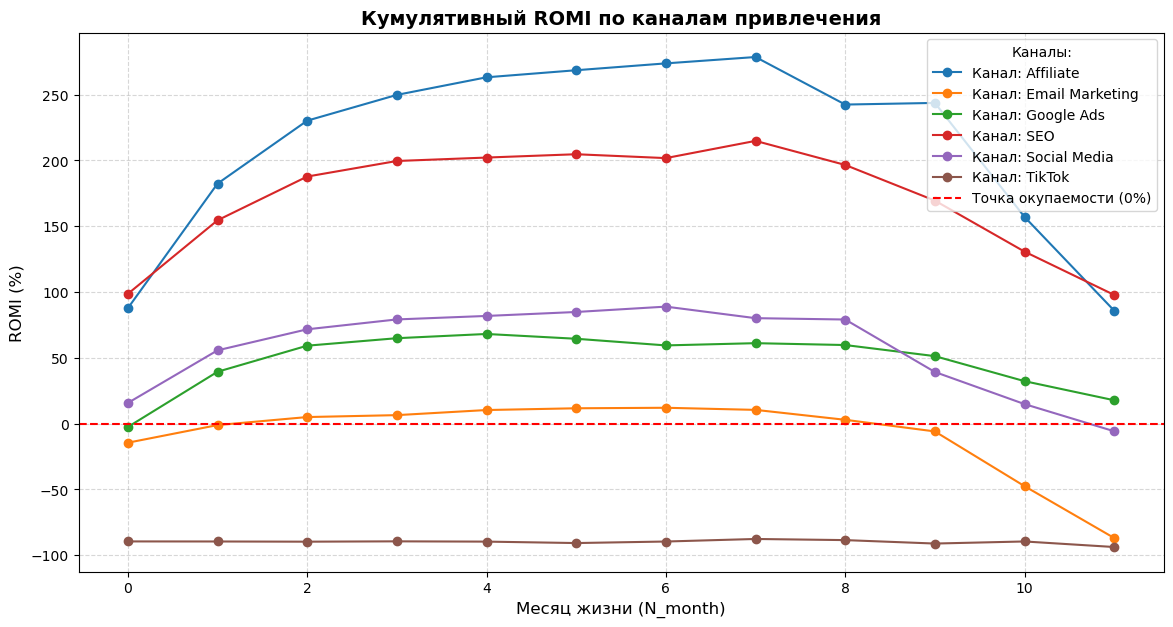

In [79]:
# ROMI канала в месяце N по суммам: только когорты, у которых этот месяц уже наступил
roi_base = df_LTV_CAC.dropna(subset=['CAC'])          # без пар, где CAC не определён

df_channel_romi = (roi_base.groupby(['acq_channel', 'N_month'])
                   .agg(revenue_sum=('LTV', 'sum'),      # накопленная выручка всех пользователей
                        spend_sum=('CAC', 'sum'))        # сумма CAC по пользователям = бюджет этих когорт
                   .reset_index())
df_channel_romi['ROMI'] = (df_channel_romi['revenue_sum'] - df_channel_romi['spend_sum']) / df_channel_romi['spend_sum'] * 100

# Если где-то бюджет был 0 → будет inf, заменяем на NaN
df_channel_romi['ROMI'] = df_channel_romi['ROMI'].replace([np.inf, -np.inf], np.nan)

plt.figure(figsize=(14, 7))

channels = df_channel_romi['acq_channel'].unique()

for channel in channels:
    df_plot = df_channel_romi[df_channel_romi['acq_channel'] == channel]
    plt.plot(df_plot['N_month'], df_plot['ROMI'], marker='o', label=f'Канал: {channel}')

plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Точка окупаемости (0%)')

plt.title('Кумулятивный ROMI по каналам привлечения', fontsize=14, fontweight='bold')
plt.xlabel('Месяц жизни (N_month)', fontsize=12)
plt.ylabel('ROMI (%)', fontsize=12)
plt.legend(title="Каналы:")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Наиболее высокий ROMI на протяжении всего периода показывает канал Affiliate: показатель достигает пика 279% на 7-м месяце, а к концу периода составляет 86%. SEO также демонстрирует высокую окупаемость: ROMI остается положительным и составляет 98% на 11-м месяце. Google Ads и Social Media выходят в плюс уже на ранних этапах, но к концу периода их ROMI снижается до 18% и -6% соответственно. TikTok остается убыточным на всем протяжении анализа: ROMI составляет около -90% и достигает -94% на 11-м месяце.

## Retention по каналам привлечения

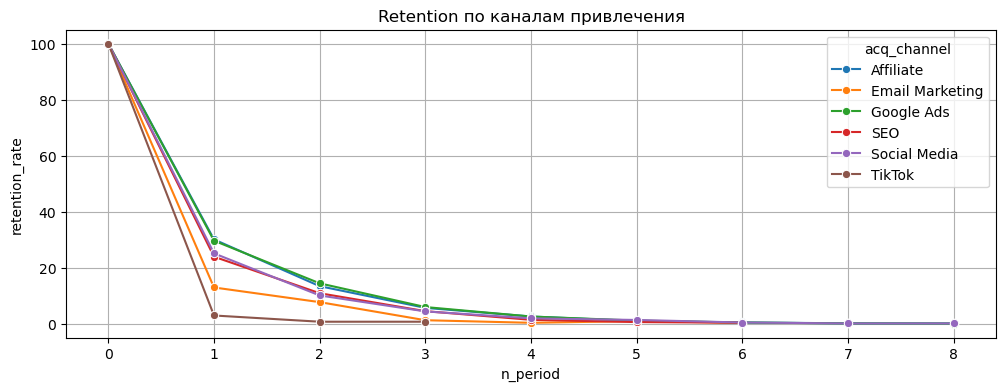

In [83]:
#  Добавляем канал в orders
df = orders.merge(users[['user_id', 'acq_channel']], on='user_id', how='left')

#  Вычисляем n_period 
df['n_period'] = (
    df['order_month'].dt.to_period('M').astype('int64')
    - df['first_order_month'].dt.to_period('M').astype('int64')
)

# Считаем Retention по каналам
retention_data = df.groupby(['acq_channel', 'n_period'])['user_id'].nunique().reset_index()

# Считаем базу для каждого канала
base_users = retention_data[retention_data['n_period'] == 0][['acq_channel', 'user_id']]
base_users.columns = ['acq_channel', 'cohort_size']

# Объединяем и считаем %
retention_data = retention_data.merge(base_users, on='acq_channel')
retention_data['retention_rate'] = retention_data['user_id'] / retention_data['cohort_size']* 100

plt.figure(figsize=(12, 4))
sns.lineplot(data=retention_data, x='n_period', y='retention_rate', hue='acq_channel', marker='o')
plt.title('Retention по каналам привлечения')
plt.grid(True)
plt.show()

Анализ Retention Rate подтверждает, что канал TikTok не только является самым дорогим с точки зрения CAC, но и привлекает наименее лояльную аудиторию: удержание пользователей здесь падает практически до нуля уже после первого периода. В то же время каналы Google Ads, SEO, Affiliate и Social Media демонстрируют схожую динамику удержания, при этом Google Ads показывает незначительно лучшие результаты на начальных этапах. Тем не менее, общая картина неутешительна: во всех без исключения каналах наблюдается резкий отток пользователей после первого периода, а к 4–5 месяцу Retention приближается к критически низким значениям. Это свидетельствует о  проблеме с удержанием в продукте, которая проявляется независимо от источника трафика.

## Сравнение новых и вернувшихся клиентов по выручке

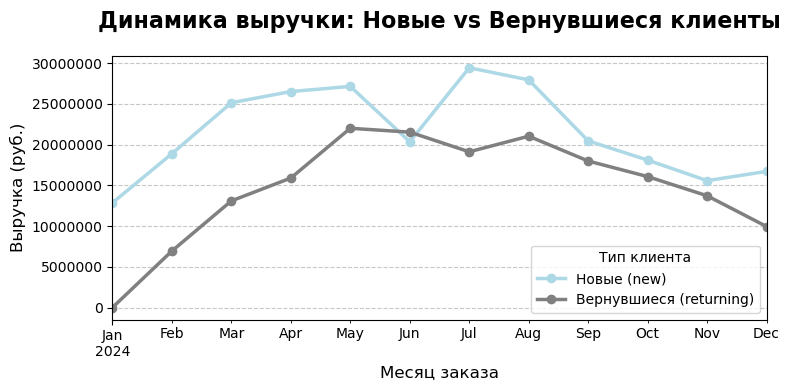

In [87]:
#  Присваиваем статус клиента (new или returning)
# Если месяц заказа совпадает с первым месяцем — клиент 'new', иначе — 'returning'
orders['customer_type'] = orders.apply(
    lambda x: 'new' if x['order_month'] == x['first_order_month'] else 'returning', axis=1
)

#  Группируем выручку по месяцу и типу клиента
revenue_by_type = orders.groupby(['order_month', 'customer_type'])['total_price'].sum().unstack().fillna(0)
plt.figure(figsize=(8, 4))

revenue_by_type.plot(
    kind='line', 
    marker='o', 
    linewidth=2.5, 
    color=['lightblue', 'gray'],
    ax=plt.gca()
)
plt.title('Динамика выручки: Новые vs Вернувшиеся клиенты', fontsize=16,fontweight='bold', pad=20)
plt.xlabel('Месяц заказа', fontsize=12)
plt.ylabel('Выручка (руб.)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title="Тип клиента", labels=['Новые (new)', 'Вернувшиеся (returning)'])
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()

plt.show()

Выручка делится на два источника: заказы новых клиентов (в месяц первой покупки) и заказы вернувшихся клиентов (в последующие месяцы). Оба источника снижаются со второго полугодия. Выручка от новых клиентов упала с 27,9 млн руб. в августе до 16,7 млн в декабре (−40%), от вернувшихся — с 21,0 до 9,9 млн (−53%). Таким образом, бизнес теряет и приток новых покупателей, и повторные заказы, а повторные снижаются заметнее: «старые» клиенты перестают покупать, а новые не компенсируют этот спад.


## Сравнение выручки и затрта по каналам

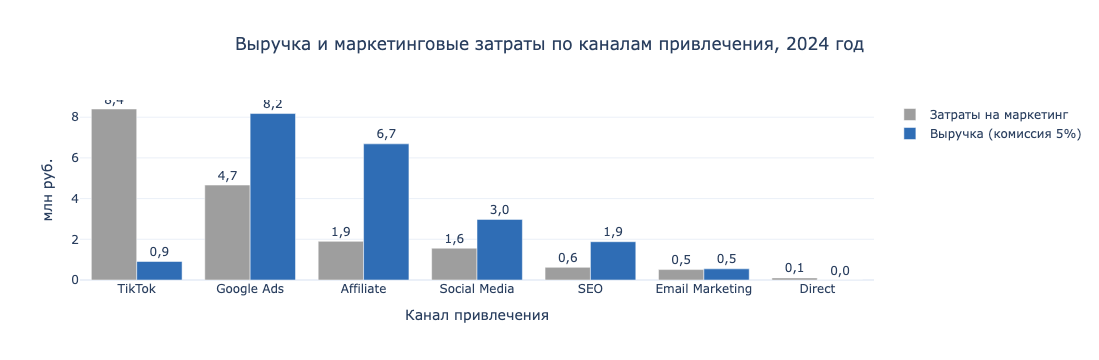

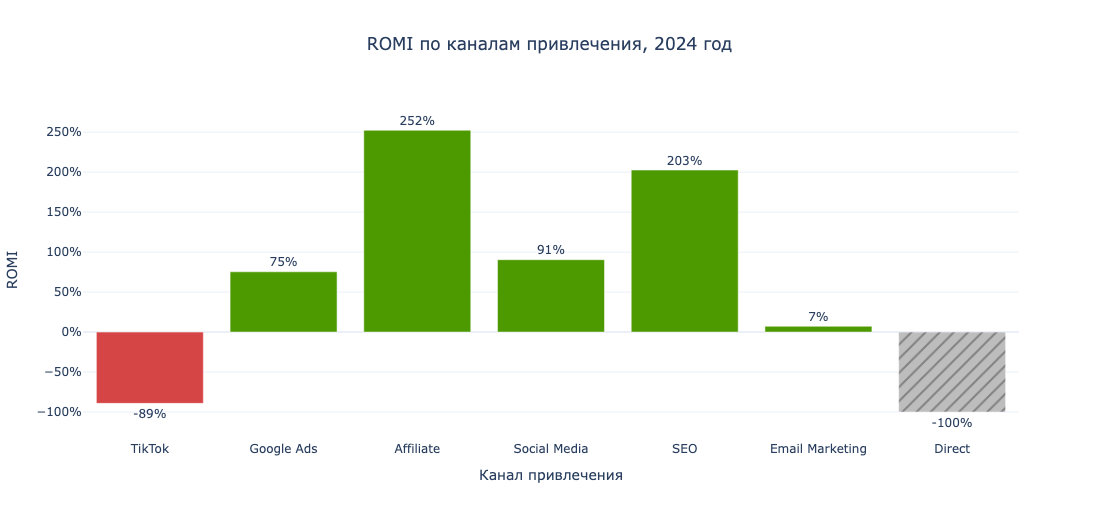

In [91]:
# Выручка по каналам (комиссия 5%)
revenue_by_channel = df_merged.groupby('acq_channel', as_index=False)['revenue'].sum()

# Затраты по каналам только за 2024 год
budget_by_channel = (
    campaign_costs[campaign_costs['spend_month'] < '2025-01-01']
    .groupby('acq_channel', as_index=False)['budget'].sum()
)

df_channel = budget_by_channel.merge(revenue_by_channel, on='acq_channel', how='left')

# У Direct нет пользователей, поэтому выручка не отнесена к каналу: считаем её равной 0
df_channel['revenue'] = df_channel['revenue'].fillna(0)

# ROMI = (выручка - маркетинговые затраты) / маркетинговые затраты
df_channel['romi'] = (df_channel['revenue'] - df_channel['budget']) / df_channel['budget']
df_channel = df_channel.sort_values('budget', ascending=False).reset_index(drop=True)

df_channel['budget_m'] = df_channel['budget'] / 1e6
df_channel['revenue_m'] = df_channel['revenue'] / 1e6

# 1. Выручка и затраты по каналам
fig = go.Figure(data=[
    go.Bar(name='Затраты на маркетинг', x=df_channel['acq_channel'], y=df_channel['budget_m'],
           marker_color='#9E9E9E', text=df_channel['budget_m'], texttemplate='%{text:.1f}', textposition='outside'),
    go.Bar(name='Выручка (комиссия 5%)', x=df_channel['acq_channel'], y=df_channel['revenue_m'],
           marker_color='#2F6DB5', text=df_channel['revenue_m'], texttemplate='%{text:.1f}', textposition='outside'),
])
fig.update_layout(
    title='Выручка и маркетинговые затраты по каналам привлечения, 2024 год',
    xaxis_title='Канал привлечения', yaxis_title='млн руб.',
    barmode='group', title_x=0.5, height=500,
    template='plotly_white', separators=', '
)
fig.show()

# 2. ROMI по каналам
is_direct = df_channel['acq_channel'] == 'Direct'
colors = ['#BDBDBD' if d else ('#4C9900' if v >= 0 else '#D64545')
          for d, v in zip(is_direct, df_channel['romi'])]

fig2 = go.Figure(go.Bar(
    x=df_channel['acq_channel'], y=df_channel['romi'],
    marker=dict(color=colors,
                pattern=dict(shape=['/' if d else '' for d in is_direct])),  # штриховка у Direct
    text=df_channel['romi'], texttemplate='%{text:.0%}', textposition='outside'
))

fig2.update_layout(
    title='ROMI по каналам привлечения, 2024 год',
    xaxis_title='Канал привлечения', yaxis_title='ROMI',
    yaxis=dict(tickformat='.0%', range=[-1.35, df_channel['romi'].max() * 1.15]),
    title_x=0.5, height=520, template='plotly_white'
)
fig2.show()

Direct: бюджет есть, но<br>пользователей с этим каналом<br>в данных нет, выручка не отнесена'

Точки роста и лидеры эффективности:

- Affiliate, Google Ads, Social Media и SEO формируют основу монетизации: во всех этих каналах доходы стабильно перекрывают вложения, обеспечивая положительный ROMI.
- Google Ads приносит наибольший объём выручки (8,2 млн руб.) при соразмерных затратах (4,7 млн руб.), оставаясь ключевым генератором дохода.
- Affiliate и SEO демонстрируют максимальную отдачу на вложенный бюджет — их ROMI достигает 252% и 203% соответственно.

Зоны убытков и низкой эффективности:

- TikTok генерирует основной минус: на канал ушёл самый крупный бюджет (8,4 млн руб.), но вернулось лишь 0,9 млн руб. (ROMI -89%), что говорит о неокупаемости текущих закупок.
- Direct при расходах около 0,1 млн руб. показал нулевую выручку (ROMI -100%). Стоит проверить корректность атрибуции трафика или пересмотреть расходы по этому направлению.
- Email Marketing балансирует около точки безубыточности (выручка и затраты на уровне 0,5 млн руб., ROMI 7%) — для масштабирования канала нужен более глубокий аудит механик.

## Маркетинговый бюджет по каналам и месяцам

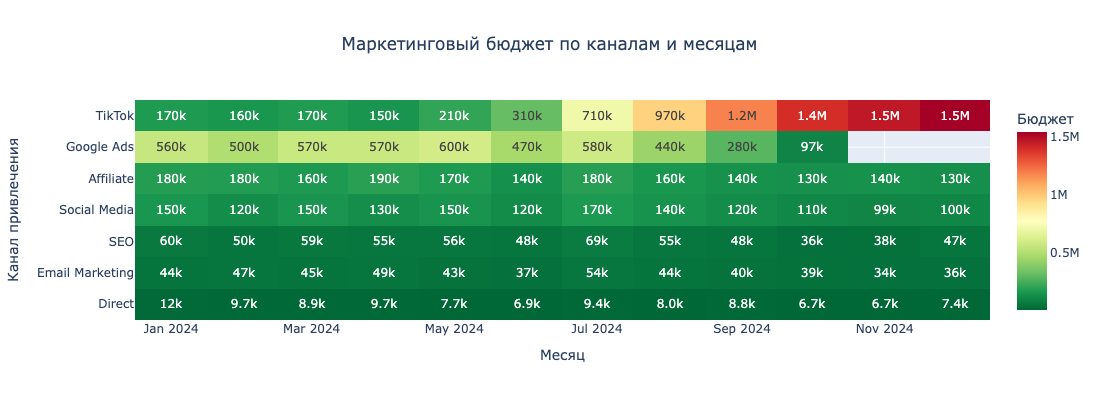

In [96]:
# Бюджет по каналам и месяцам
costs_plot = campaign_costs.copy()
costs_plot['spend_month'] = costs_plot['spend_month'].dt.strftime('%Y-%m')   # короткие подписи месяцев

pivot_budget_channel = costs_plot.pivot_table(index='acq_channel',
                                              columns='spend_month',
                                              values='budget',
                                              aggfunc='sum')

# Каналы упорядочиваем по суммарному бюджету (самый большой сверху)
pivot_budget_channel = pivot_budget_channel.loc[pivot_budget_channel.sum(axis=1).sort_values(ascending=False).index]

fig = px.imshow(pivot_budget_channel,
                title='Маркетинговый бюджет по каналам и месяцам',
                labels=dict(x='Месяц', y='Канал привлечения', color='Бюджет'),
                color_continuous_scale='RdYlGn_r',
                text_auto='.2s',
                aspect='auto')

fig.update_layout(title_x=0.5, height=400, xaxis_title='Месяц', yaxis_title='Канал привлечения')
fig.show()

Маркетинговые расходы распределены между каналами неравномерно. Основная часть бюджета приходится на Google Ads и TikTok. При этом динамика этих каналов заметно меняется во втором полугодии: расходы на Google Ads сокращаются, а инвестиции в TikTok начинают быстро расти с июля (710 тыс.) и достигают 1,5 млн в ноябре и декабре.

Бюджеты Affiliate и Social Media остаются относительно стабильными: около 130–190 тыс. и 100–170 тыс. в месяц соответственно. SEO, Email Marketing и Direct получают значительно меньше средств, без существенных изменений в течение года.

Особого внимания заслуживает TikTok: увеличение расходов на этот канал с июля совпадает по времени с общим снижением выручки маркетплейса. К ноябрю и декабрю бюджет TikTok достигает 1,5 млн, тогда как выручка продолжает снижаться. С учетом того, что ранее мы увидели отрицательный ROMI TikTok на протяжении всего периода, это может указывать на неэффективное перераспределение маркетингового бюджета. 

**Промежуточный вывод**

Эффективность каналов привлечения существенно различается: Affiliate и SEO показывают наибольшую отдачу (ROMI 252% и 203%), Google Ads приносит максимальную выручку (8,2 млн руб.), тогда как TikTok остается убыточным (ROMI −89%) при самом высоком CAC. Несмотря на это, с июля бюджет TikTok активно увеличивается и к концу года достигает 1,5 млн руб. в месяц.

Параллельно снижается Retention практически во всех каналах, что приводит к сокращению выручки от повторных покупок. С июня также падает доход от новых клиентов, поэтому бизнес теряет оба источника выручки.

##  Поиск инсайтов, точек роста и сегментация

На этом этапе анализ переходит с агрегированных метрик и каналов на уровень поведения пользователей. Цель: понять, на каких шагах пути к заказу аудитория теряется сильнее всего и какие группы пользователей приносят основную выручку, а какие почти не приносят. На этой основе определяются проблемные места продукта и точки роста.

Последовательно рассматриваются:

- пользовательская воронка от регистрации до заказа: на каких шагах охват аудитории снижается сильнее всего;
- воронки в разрезе устройств и операционных систем: объясняет ли платформа потери на отдельных шагах;
- воронка по каналам привлечения: как отличается качество трафика из разных каналов и до какого шага доходят пользователи каждого канала;
- сегменты покупателей (one_time, rare, medium, regular): размер сегментов, конверсия и LTV;
- распределение стоимости заказов: типичный чек и доля крупных заказов;
- RFM-сегментация: какие пользователи покупали недавно, часто и на большие суммы, а какие перестали возвращаться.

Результат этапа: список узких мест в пользовательском пути, сильные и слабые сегменты пользователей, на которых затем основываются выводы и продуктовые гипотезы.

## Анализ пользовательского пути

Посмотрим, как пользователи проходят путь от регистрации до заказа и на каких шагах аудитория сокращается сильнее всего. В воронку включены ключевые действия на сайте: просмотры страниц и товаров, клики, добавление в корзину, оформление заказа и итоговая покупка.

На маркетплейсе путь пользователя редко бывает линейным: люди переключаются между разделами, возвращаются к уже просмотренным товарам, ищут и фильтруют в произвольном порядке, а в корзину добавляют, не обязательно пройдя все промежуточные шаги. К тому же по данным событий нельзя надёжно восстановить порядок действий внутри одной сессии. Поэтому воронка показывает не строгую последовательность, а охват: сколько уникальных пользователей совершило каждое действие хотя бы раз. Конверсия между шагами здесь означает отношение охватов соседних шагов, а не долю тех, кто прошёл их друг за другом.

,step,users,conversion_from_first_%,conversion_from_previous_%
0,registration,44151,100.0,NaN
1,page_view,22098,50.1,50.1
2,product_view,22069,50.0,99.9
3,product_click,21745,49.3,98.5
4,add_to_cart,20411,46.2,93.9
5,checkout_start,16769,38.0,82.2
6,checkout_complete,13897,31.5,82.9
7,order_placed,8922,20.2,64.2


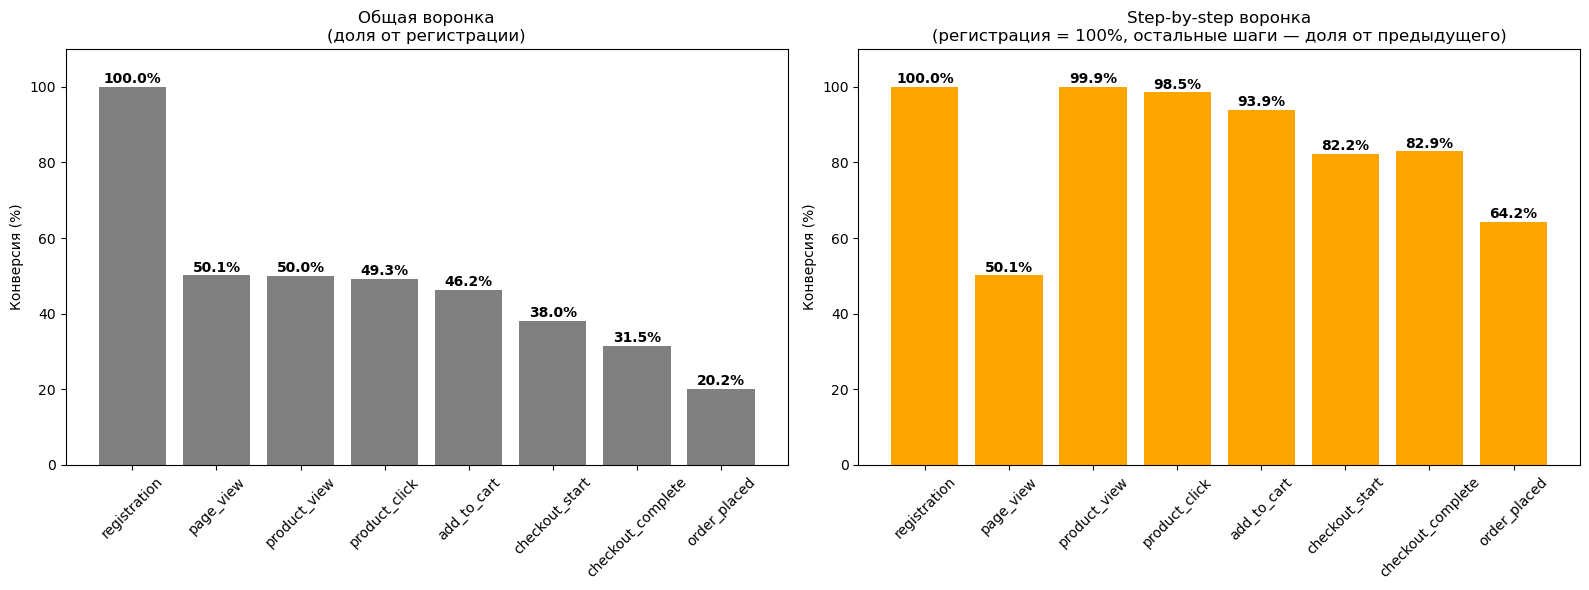

In [104]:
# Задаем порядок шагов в воронке
event_steps = ['page_view', 'product_view', 'product_click',
               'add_to_cart', 'checkout_start', 'checkout_complete']

# Число уникальных пользователей на каждом шаге из событий
funnel_counts = (events[events['event_type'].isin(event_steps)]
                 .groupby('event_type')['user_id'].nunique()
                 .reindex(event_steps))

# Первый шаг — регистрация (все пользователи из users), последний — реальные заказы из orders
registered_users = users['user_id'].nunique()
orders_users = orders['user_id'].nunique()

funnel_steps_full = ['registration'] + event_steps + ['order_placed']
funnel_counts_full = [registered_users] + list(funnel_counts.values) + [orders_users]

# Собираем таблицу воронки
funnel_df = pd.DataFrame({
    'step': funnel_steps_full,
    'users': funnel_counts_full
})

# Добавляем конверсии
funnel_df['conversion_from_first_%'] = (funnel_df['users'] / funnel_df['users'].iloc[0] * 100).round(1)
funnel_df['conversion_from_previous_%'] = (funnel_df['users'] / funnel_df['users'].shift(1) * 100).round(1)

display(funnel_df)

# Данные для двух графиков
steps_all = funnel_df['step']
values_first = funnel_df['conversion_from_first_%']                      # доля от регистрации
values_prev = funnel_df['conversion_from_previous_%'].fillna(100)        # доля от предыдущего шага, у регистрации база 100%

colors_prev = 'orange'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ГРАФИК 1: Общая воронка (от регистрации)
ax1.bar(steps_all, values_first, color='gray')
ax1.set_title('Общая воронка\n(доля от регистрации)', fontsize=12)
ax1.set_ylabel('Конверсия (%)')
ax1.set_ylim(0, max(values_first) + 10)
ax1.tick_params(axis='x', rotation=45)
for i, val in enumerate(values_first):
    ax1.text(i, val + 1, f'{val}%', ha='center', fontweight='bold')

# ГРАФИК 2: Step-by-step воронка
ax2.bar(steps_all, values_prev, color=colors_prev)
ax2.set_title('Step-by-step воронка\n(регистрация = 100%, остальные шаги — доля от предыдущего)', fontsize=12)
ax2.set_ylabel('Конверсия (%)')
ax2.set_ylim(0, max(values_prev) + 10)
ax2.tick_params(axis='x', rotation=45)
for i, val in enumerate(values_prev):
    ax2.text(i, val + 1, f'{val}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

Наибольшее снижение происходит на входе: около половины зарегистрированных пользователей (50%) не совершает после регистрации ни одного просмотра страниц и товаров. Возможные причины: онбординг, качество трафика или технические сбои после регистрации.

Второе по величине снижение — на последнем шаге: из пользователей, завершивших оформление, заказ размещают 64%, то есть примерно каждый третий не доходит до заказа. Причины стоит искать в ошибках и ограничениях платежей, неожиданных сборах или стоимости доставки, проблемах с валидацией адреса, технических сбоях на последнем экране.

Основные потери аудитории приходятся на вход в продукт и на последний шаг оформления покупки. Чтобы понять, зависят ли они от источника трафика, воронка рассматривается в разрезе устройств и каналов привлечения.

## Воронки в развере устройств и ОС

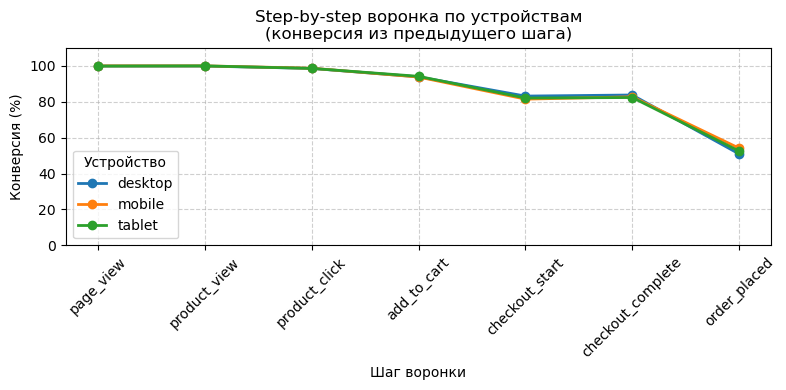

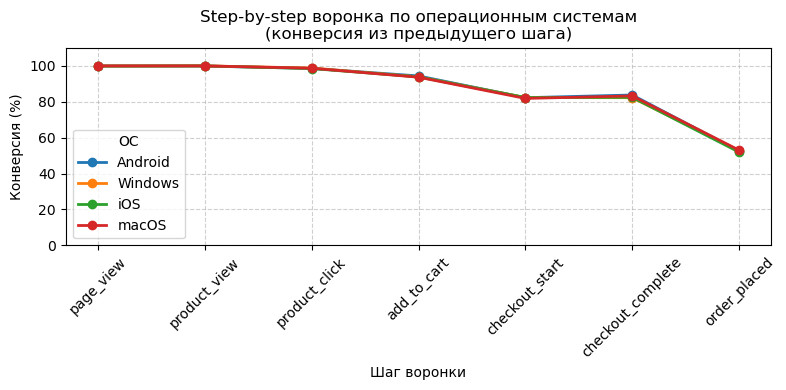

In [108]:
# Шаги воронки для устройств и ОС: первый шаг — пользователи с событиями
steps_full = ['active_users'] + event_steps + ['order_placed']
def funnel_by(column):
    """Воронка step-by-step в разрезе столбца events (device или os). Возвращает две сводные таблицы."""
    rows = []
    for value in events[column].dropna().unique():
        ev = events[events[column] == value]
        counts = (ev[ev['event_type'].isin(event_steps)]
                  .groupby('event_type')['user_id'].nunique()
                  .reindex(event_steps))
        group_users = ev['user_id'].unique()
        orders_users = orders[orders['user_id'].isin(group_users)]['user_id'].nunique()
        rows.append(pd.DataFrame({
            'step': steps_full,
            column: value,
            'users': [len(group_users)] + list(counts.values) + [orders_users]
        }))
    df = pd.concat(rows, ignore_index=True)
    df['conversion_%'] = df['users'] / df.groupby(column)['users'].shift(1) * 100
    pivot_users = df.pivot(index='step', columns=column, values='users').reindex(steps_full)
    pivot_conv = df.pivot(index='step', columns=column, values='conversion_%').reindex(steps_full).round(1)
    return pivot_users, pivot_conv


def plot_funnel(pivot_conv, title, legend_title):
    """Линейный график: все группы на одном полотне, без базового шага."""
    fig, ax = plt.subplots(figsize=(8, 4))
    for name in pivot_conv.columns:
        values = pivot_conv[name].iloc[1:]
        ax.plot(values.index, values.values, marker='o', linewidth=2, label=name)
    ax.set_title(f'{title}\n(конверсия из предыдущего шага)', fontsize=12)
    ax.set_xlabel('Шаг воронки')
    ax.set_ylabel('Конверсия (%)')
    ax.set_ylim(0, 110)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(title=legend_title)
    plt.tight_layout()
    plt.show()


# По устройствам
users_dev, conv_dev = funnel_by('device')
plot_funnel(conv_dev, 'Step-by-step воронка по устройствам', 'Устройство')

# По операционным системам
users_os, conv_os = funnel_by('os')
plot_funnel(conv_os, 'Step-by-step воронка по операционным системам', 'ОС')

Воронки по устройствам и операционным системам практически не различаются: до шага checkout_complete конверсия между соседними шагами отличается не более чем на 2 п.п., а на последнем переходе checkout_complete → order_placed она составляет 51–54% во всех группах. Платформа не объясняет потерь на этапе оплаты, поэтому причины стоит искать в других срезах, например по каналам привлечения. 

## Воронка по канал привлечения

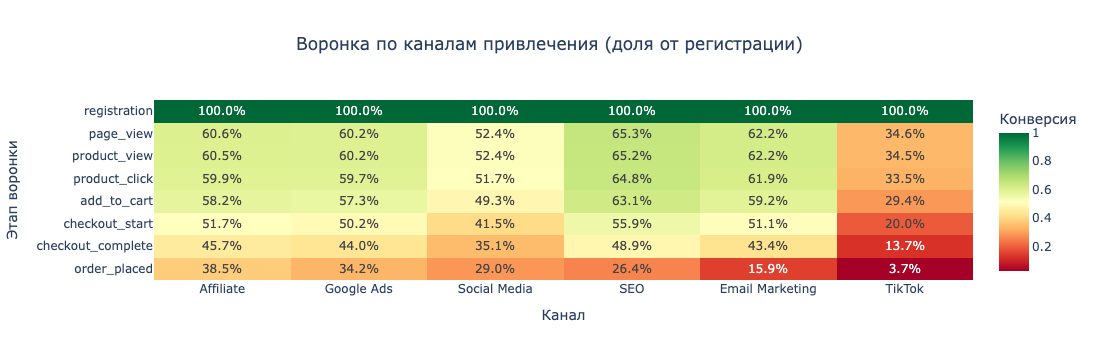

In [112]:
# Канал привлечения для каждого пользователя
channel_map = users[['user_id', 'acq_channel']]
steps_ch = ['registration'] + event_steps + ['order_placed']

# Регистрации: все пользователи канала
reg = users.groupby('acq_channel')['user_id'].nunique().rename('registration')

# События: уникальные пользователи на каждом шаге (события пользователей без записи в users отбрасываются)
events_ch = (events[events['event_type'].isin(event_steps)]
             .merge(channel_map, on='user_id', how='inner'))
ev = (events_ch.groupby(['acq_channel', 'event_type'], observed=True)['user_id']
      .nunique().unstack().reindex(columns=event_steps))

# Заказы: уникальные покупатели канала
ordr = (orders.merge(channel_map, on='user_id', how='inner')
        .groupby('acq_channel')['user_id'].nunique().rename('order_placed'))

# Таблица: каналы по строкам, шаги по столбцам
funnel_ch = pd.concat([reg, ev, ordr], axis=1)[steps_ch]

# Конверсия от регистрации (включая шаг registration = 1.0 / 100%)
conv_from_reg = funnel_ch.div(funnel_ch['registration'], axis=0).round(3)

# Каналы упорядочиваем по конверсии на последнем шаге
conv_from_reg = conv_from_reg.sort_values('order_placed', ascending=False)

# Для карты: шаги по строкам, каналы по столбцам
pivot_funnel_channels = conv_from_reg.T

fig = px.imshow(pivot_funnel_channels,
                title='Воронка по каналам привлечения (доля от регистрации)',
                labels=dict(x='Канал', y='Этап воронки', color='Конверсия'),
                color_continuous_scale='RdYlGn',
                text_auto='.1%',
                aspect='auto')

fig.update_layout(title_x=0.5, height=450, xaxis_title='Канал', yaxis_title='Этап воронки')
fig.show()

Affiliate и Google Ads показывают лучшее качество трафика: до заказа доходит 34–39% зарегистрированных пользователей.
Social Media, SEO и Email Marketing занимают промежуточное положение (16–29% доходят до заказа).
TikTok заметно отстает от остальных каналов: действия на сайте совершает лишь 35% зарегистрированных, а до заказа доходит 3,7%. Это канал, где конверсия в первую покупку наименьшая

## Анализ пользователей по сегментам 

In [116]:
# Создаем таблицу с базовой статистикой пользователей по сегментам
buyer_segment_info = users.groupby('buyer_segment').agg(
    {'user_id': 'count'}
).reset_index().rename(columns={
    'buyer_segment': 'Сегмент покупателя', 
    'user_id': 'Кол-во пользователей'
})

# Добавляем долю пользователей в процентах
total_users = buyer_segment_info['Кол-во пользователей'].sum()
buyer_segment_info['Доля, %'] = (buyer_segment_info['Кол-во пользователей'] / total_users * 100).round(2)

#  Готовим данные для конверсии: находим уникальных покупателей по сегментам
# Берем всех, кто есть в orders (уникальные user_id)
paid_users_per_segment = orders.merge(users[['user_id', 'buyer_segment']], on='user_id')['user_id'].unique()

# Считаем количество платящих пользователей в каждом сегменте
paid_stats = users.copy()
paid_stats['is_paid'] = paid_stats['user_id'].isin(paid_users_per_segment).astype(int)
cr_data = paid_stats.groupby('buyer_segment')['is_paid'].agg(['sum', 'count']).reset_index()

#  Считаем LTV (средняя выручка на ВСЕХ пользователей в сегменте, даже если 0)
revenue_per_user = orders.groupby('user_id')['revenue'].sum().reset_index()
ltv_data = users[['user_id', 'buyer_segment']].merge(revenue_per_user, on='user_id', how='left')
ltv_data['revenue'] = ltv_data['revenue'].fillna(0)
ltv_stats = ltv_data.groupby('buyer_segment')['revenue'].mean().reset_index()

#  Объединяем всё в одну таблицу
final_df = buyer_segment_info.copy()

# Добавляем CR: переименуем столбец в cr_data прямо перед мерджем, чтобы не плодить дубли
final_df = final_df.merge(cr_data.rename(columns={'buyer_segment': 'Сегмент покупателя'}), on='Сегмент покупателя')
final_df['Конверсия, %'] = (final_df['sum'] / final_df['count'] * 100).round(2)

# Добавляем LTV: также переименуем перед мерджем
final_df = final_df.merge(ltv_stats.rename(columns={'buyer_segment': 'Сегмент покупателя'}), on='Сегмент покупателя')

# Переименовываем выручку в LTV (округляем только этот столбец, а не всю таблицу)
final_df = final_df.rename(columns={'revenue': 'Средний LTV (руб.)'})
final_df['Средний LTV (руб.)'] = final_df['Средний LTV (руб.)'].round(2)

#  Оставляем только нужные столбцы
final_table = final_df[['Сегмент покупателя', 'Кол-во пользователей', 'Доля, %', 'Конверсия, %', 'Средний LTV (руб.)']]

display(final_table)

,Сегмент покупателя,Кол-во пользователей,"Доля, %","Конверсия, %",Средний LTV (руб.)
0,medium,16421,37.19,22.48,315.17
1,one_time,6701,15.18,3.85,32.96
2,rare,13256,30.02,7.45,78.87
3,regular,7773,17.61,47.81,1896.51


Основная ценность сосредоточена в regular: при доле 17,6% (7 773 чел.) он показывает конверсию 47,8% и средний LTV 1 897 руб., что в 6 раз выше, чем у medium (315 руб.), и в 24 раза выше, чем у rare (79 руб.). На этот сегмент приходится около 70% выручки. Сегменты rare и one_time (45% базы) имеют конверсию 4–7% и LTV до 79 руб. и почти не приносят дохода. Бизнес зависит от небольшой группы активных покупателей, а у остальных сегментов основной резерв роста — конверсия в первую покупку.

## Распределение стоимости заказа

count     31087.000000
mean      14038.536028
std       18688.925397
min         339.000000
50%        7554.640000
60%       10348.530000
70%       14652.030000
80%       20600.700000
95%       47093.640000
99%       94444.830000
max      191797.140000
Name: total_price, dtype: float64


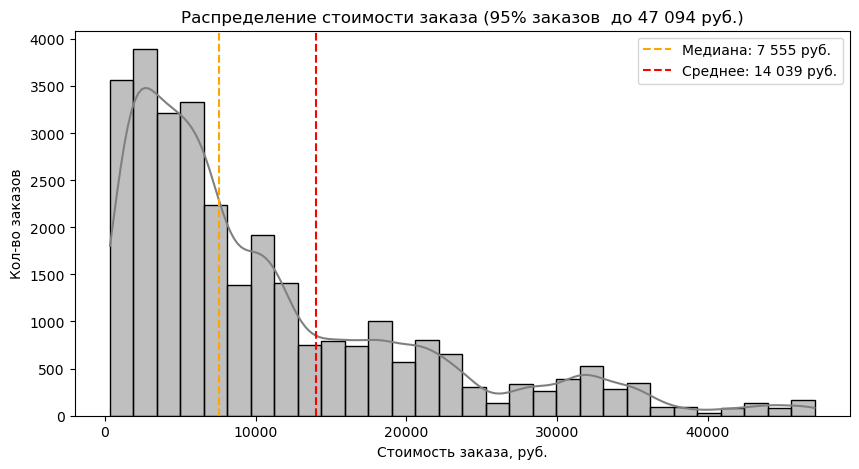

In [120]:
print(orders['total_price'].describe(percentiles=[0.5, 0.6, 0.7, 0.8, 0.95, 0.99]))

p95 = orders['total_price'].quantile(0.95)
median = orders['total_price'].median()
mean = orders['total_price'].mean()

plt.figure(figsize=(10, 5))
sns.histplot(data=orders[orders['total_price'] <= p95], x='total_price', bins=30, kde=True, color='gray')

plt.axvline(median, color='orange', linestyle='--', label=f'Медиана: {median:,.0f} руб.'.replace(',', ' '))
plt.axvline(mean, color='red', linestyle='--', label=f'Среднее: {mean:,.0f} руб.'.replace(',', ' '))

plt.title(f'Распределение стоимости заказа (95% заказов, до {p95:,.0f} руб.)'.replace(',', ' '))
plt.xlabel('Стоимость заказа, руб.')
plt.ylabel('Кол-во заказов')
plt.legend()
plt.show()

Гистограмма построена по заказам до 95-го перцентиля (до 47 094 руб.). Оставшиеся 5% заказов растягиваются до 191 797 руб. и сжали бы основную часть распределения в несколько левых столбцов, по которым ничего не разглядеть. Статистика (медиана, среднее, перцентили) и вертикальные линии медианы и среднего рассчитаны по всем заказам, а не только по обрезанным.

Распределение сильно скошено вправо: медианный чек 7 555 руб., средний 14 039 руб., то есть среднее почти вдвое выше за счёт крупных заказов. Основная масса заказов приходится на чеки примерно до 7 тыс. руб., а 80% заказов не превышают 20,6 тыс. руб. Есть также небольшая группа заказов на 30–35 тыс. руб. Верхние 5% заказов (от 47 тыс. руб. до 192 тыс. руб.) малочисленны, но сильно повышают средний чек. Поэтому для оценки типичной покупки лучше ориентироваться на медиану, а не на среднее.

## RFM анализ

   user_id  recency  frequency  monetary_value
0        3      341          7       4359.5615
1        5      292         14       7068.9900
2        6      251          2        369.5760
3        8      314          7       2270.0685
4       12      347          2        302.0060


Text(0, 0.5, 'Количество пользователей')

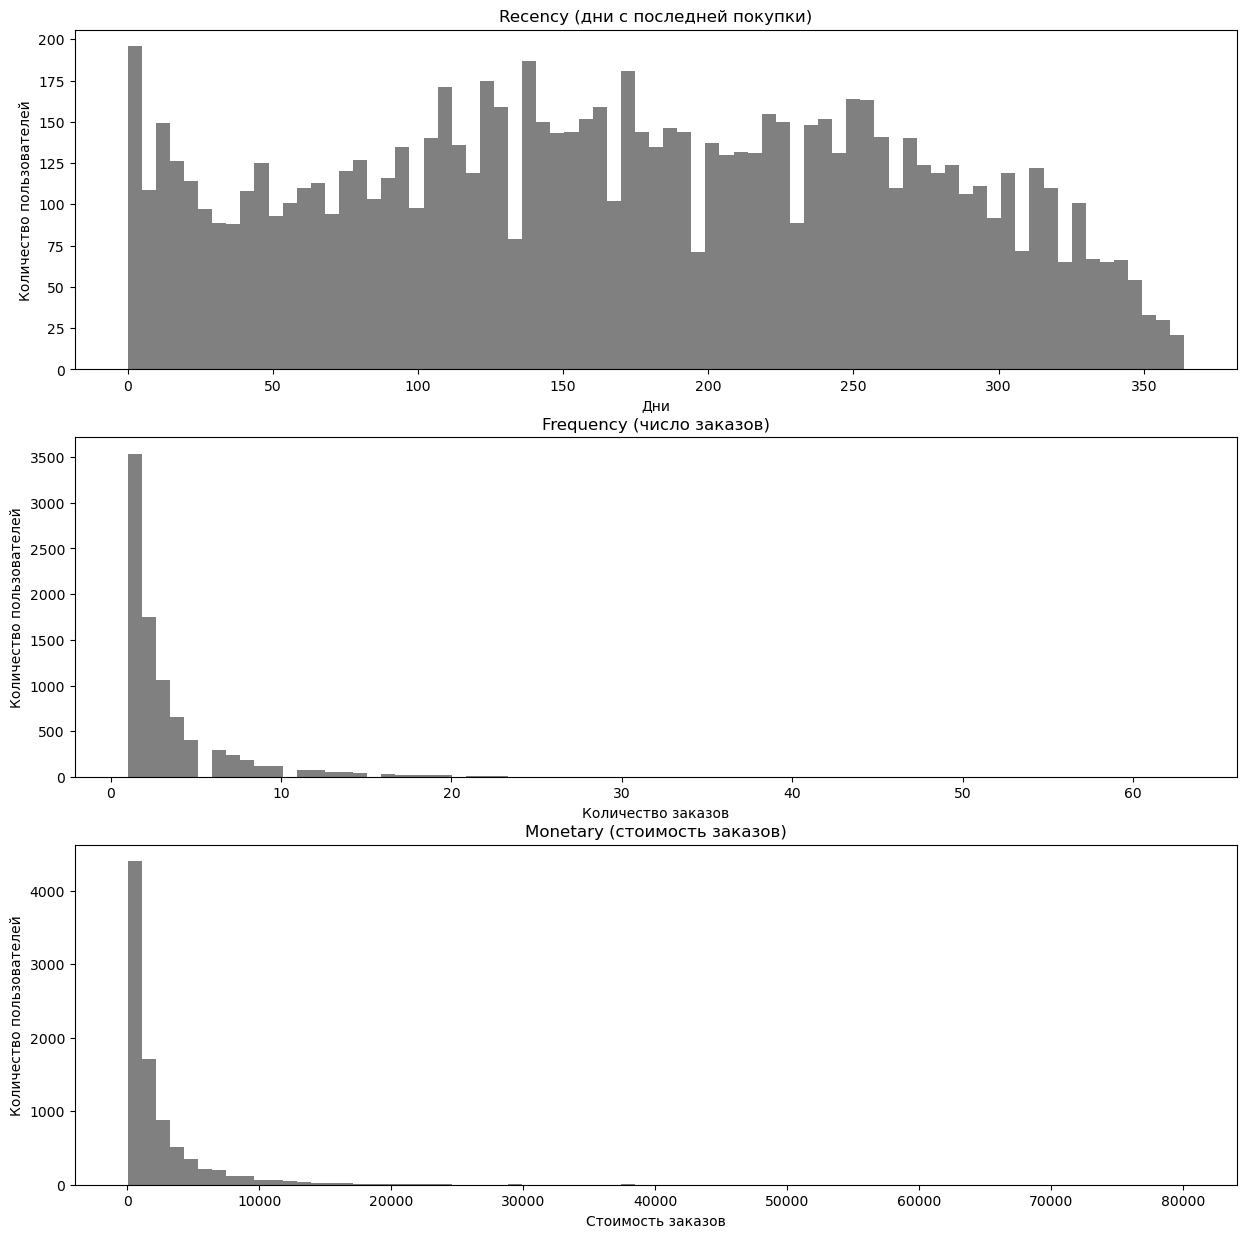

In [126]:
#  Рассчитываем Recency с учетом времени последнего заказа ( чтобы вошли заказы за все время 31 декабря)
analysis_date = pd.to_datetime('2024-12-31 23:59:59')
orders['order_recency'] = analysis_date - orders['order_date']

#  Группируем данные (теперь в order_recency корректные значения)
ppro_rfm = orders.groupby('user_id').agg(
    # Берем min(), так как чем меньше дней, тем свежее покупка
    recency = ('order_recency', lambda x: x.min().days),
    frequency = ('order_id', 'count'),
    monetary_value = ('revenue', 'sum')
).reset_index()

print(ppro_rfm.head(5))

fig, axes = plt.subplots(3, 1, figsize=(15, 15))


# Давность
axes[0].hist(ppro_rfm['recency'], bins=75,color='gray')
axes[0].set_title('Recency (дни с последней покупки)')
axes[0].set_xlabel('Дни')
axes[0].set_ylabel('Количество пользователей')

# Частота
axes[1].hist(ppro_rfm['frequency'], bins=75,color='gray')
axes[1].set_title('Frequency (число заказов)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество пользователей')

# Сумма всех заказов
axes[2].hist(ppro_rfm['monetary_value'], bins=75,color='gray')
axes[2].set_title('Monetary (стоимость заказов)')
axes[2].set_xlabel('Стоимость заказов')
axes[2].set_ylabel('Количество пользователей')

In [156]:
# Определяем группу пользователя по количеству дней с момента последнего заказа: 
ppro_rfm['r'] = pd.cut(ppro_rfm['recency'], bins=3, labels=[3,2,1])

# Определяем группу пользователя по количеству заказов: 
ppro_rfm['f'] = pd.cut(ppro_rfm['frequency'], bins=[0, 1, 2, float('inf')], labels=[1, 2, 3], include_lowest=True)

# Определяем группу пользователя по сумме стоимости заказов: 
ppro_rfm['m'] = pd.qcut(ppro_rfm['monetary_value'], q=3, labels=[1, 2, 3])
# Находим групповой RFM-индекс:
ppro_rfm[['r','f','m']] = ppro_rfm[['r','f','m']].astype('str')
ppro_rfm['rfm_group'] = ppro_rfm['r'] + ppro_rfm['f'] + ppro_rfm['m']

# Выводим первые строки таблицы:
print(ppro_rfm.head(3))

   user_id  recency  frequency  monetary_value  r  f  m rfm_group
0        3      341          7       4359.5615  1  3  3       133
1        5      292         14       7068.9900  1  3  3       133
2        6      251          2        369.5760  1  2  1       121


In [159]:
# 1. Группируем и считаем показатели
rfm_group = ppro_rfm.groupby('rfm_group').agg({'user_id': 'nunique'}).reset_index()
rfm_group['user_share'] = (rfm_group['user_id'] / rfm_group['user_id'].sum() * 100).round(1)

# 2. Сортируем и берем первые 5 строк
top5_rfm = rfm_group.sort_values(by='user_id', ascending=False).head(5)

# Выводим результат
top5_rfm

,rfm_group,user_id,user_share
17,233,1022,11.5
26,333,888,10.0
9,211,869,9.7
0,111,742,8.3
18,311,705,7.9


**RFM-анализ: ключевые выводы**

Наиболее ценные сегменты — 333 (10% покупателей) и 233 (11,5%). Они формируют высокую выручку и имеют 3+ транзакции. При этом покупатели сегмента 333 совершали покупки наиболее недавно, а 233 — менее активно в последнее время. Приоритет — удержание сегмента 333 и реактивация сегмента 233.

Около 26% покупателей относятся к сегментам 211, 311 и 111: у них только одна транзакция за период наблюдения и низкая выручка. Это основной резерв для роста повторных покупок, особенно среди тех, кто давно не совершал транзакций.

Частота транзакций и выручка распределены неравномерно: основная часть покупателей совершает мало транзакций и приносит небольшую выручку, тогда как значительная доля выручки сосредоточена у небольшой группы активных покупателей.

## Итоги исследования и направления для развития

### 1. Динамика бизнеса: снижение активности и повторных покупок

В первой половине 2024 года маркетплейс рос, однако во втором полугодии динамика заказов, комиссионной выручки и пользовательской активности развернулась в сторону снижения. Одновременно снизилось удержание платящих пользователей: доля покупателей, совершивших повторный заказ в следующем месяце после первой покупки, сократилась с **35%** у январской когорты до **19%** у ноябрьской. В большинстве когорт повторные покупки резко сокращаются уже после первого месяца, а к 4–5 месяцу доля вернувшихся приближается к нулю. Это указывает на низкое долгосрочное удержание покупателей.

### 2. Эффективность привлечения: существенная разница между каналами

Экономика каналов привлечения заметно различается. **Affiliate и SEO** показывают наиболее высокую отдачу: ROMI составляет **252% и 203%** соответственно. CAC в этих каналах находится в диапазонах **648–1 587 руб** и **610–1 194 руб**.

Наиболее дорогим каналом оказался **TikTok**: CAC варьируется от **8 389 руб до 24 304 руб**, а ROMI составляет **−89%**. При этом Google Ads обеспечил выручку площадки около **8,2 млн руб.**, но в ноябре и декабре данные по CAC для него отсутствуют.

Таким образом, проблема заключается не только в объеме маркетинговых расходов, но и в их распределении. Affiliate и SEO демонстрируют более привлекательную экономику привлечения, тогда как TikTok требует отдельной проверки причин низкой конверсии и высокой стоимости платящего пользователя.

### 3. Пользовательская воронка: точки потери потенциальных покупателей

Анализ событий позволяет выделить этапы, на которых пользователи не переходят к следующим действиям. Это дает основания рассматривать проблему не только на уровне маркетинговых каналов, но и внутри самого продукта: от первого взаимодействия с площадкой до оформления заказа.


### 4. Покупательская база: потенциал повторных продаж

RFM-анализ охватил **8 922 покупателей**, совершивших хотя бы одну транзакцию за период наблюдения. Наиболее ценные группы — 333 и 233 — включают **888 (10%) и 1 022 (11,5%) покупателей** соответственно. Обе группы характеризуются высокой частотой покупок (3 и более транзакций) и высокой суммарной выручкой.

Это подтверждает значимость работы с повторными покупками: пользователи, которые возвращаются на площадку, формируют заметную часть покупательской ценности. Следовательно, развитие удержания и стимулирование следующей покупки могут быть отдельными направлениями роста наряду с привлечением новой аудитории.

### 5. Гипотезы для дальнейшей проверки

**Гипотеза 1. Повысить конверсию новых пользователей TikTok в первую покупку.**

Если предложить новым пользователям TikTok бонус на первую покупку, то конверсия в заказ может вырасти, а стоимость привлечения платящего пользователя — снизиться.

Основание: TikTok имеет самую слабую экономику среди рассмотренных каналов: CAC достигает 24 304 руб, ROMI составляет −89%. При этом канал уже обеспечивает приток аудитории. Низкая эффективность может быть связана не только с качеством трафика, но и с недостаточной мотивацией новых пользователей совершить первую покупку.

**Гипотеза 2. Увеличить долю повторных покупок.**

Если разработать механики возврата покупателей — персональные предложения, рекомендации товаров или бонусы за следующую покупку, — можно повысить Retention и увеличить выручку от существующей аудитории.

Основание: Retention платящих пользователей снизился с 35% до 19%, а RFM-анализ показывает наличие группы покупателей с высокой частотой и денежной ценностью.

**Гипотеза 3. Пересмотреть распределение маркетингового бюджета.**

Если увеличить долю расходов на каналы с более высоким ROMI — Affiliate и SEO — и отдельно оптимизировать TikTok, можно повысить общую отдачу от маркетинговых инвестиций.

Основание: ROMI Affiliate и SEO составляет 252% и 203%, тогда как TikTok показывает −89%. При этом решение о полном отключении TikTok преждевременно без проверки возможности повысить конверсию уже привлекаемой аудитории.

### 6. Следующий шаг: проверка гипотезы по TikTok

Несмотря на текущую отрицательную окупаемость, TikTok имеет смысл не отключать сразу, а выделить для него ограниченный тестовый бюджет. Канал уже приводит новых пользователей, и эксперимент позволит проверить, можно ли улучшить экономику привлечения за счет повышения конверсии в первую покупку.

Поэтому следующим шагом становится A/B-тест бонуса для новых пользователей TikTok. Его основная задача — выяснить, увеличивает ли бонус конверсию в первую покупку и сопровождается ли этот рост положительной динамикой выручки, не ухудшая качество платящих пользователей.
